<a href="https://colab.research.google.com/github/csnvvaish/Fetal_health/blob/ctg-assist-development/fetal_health_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.simplefilter(action='ignore')

from collections import Counter
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pandas as pd
file_path = r'/content/fetal_health.csv'

if os.path.exists(file_path):
    df = pd.read_csv(r'/content/fetal_health.csv')
    print('File found and loaded successfully')
else:
    print("File not found at the specified path.")
    print("File not found at the specified path.")

File found and loaded successfully


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import learning_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import learning_curve

In [ ]:
fetal_data=pd.read_csv("fetal_health.csv")
fetal_data.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [ ]:
fetal_data.shape

(2126, 22)

In [ ]:
print(f"Dataset columns: {fetal_data.columns}")

Dataset columns: Index(['baseline value', 'accelerations', 'fetal_movement',
       'uterine_contractions', 'light_decelerations', 'severe_decelerations',
       'prolongued_decelerations', 'abnormal_short_term_variability',
       'mean_value_of_short_term_variability',
       'percentage_of_time_with_abnormal_long_term_variability',
       'mean_value_of_long_term_variability', 'histogram_width',
       'histogram_min', 'histogram_max', 'histogram_number_of_peaks',
       'histogram_number_of_zeroes', 'histogram_mode', 'histogram_mean',
       'histogram_median', 'histogram_variance', 'histogram_tendency',
       'fetal_health'],
      dtype='object')


In [ ]:
fetal_data.describe().T

,count,mean,std,min,25%,50%,75%,max
baseline value,2126.0,133.303857,9.840844,106.0,126.000,133.000,140.000,160.000
accelerations,2126.0,0.003178,0.003866,0.0,0.000,0.002,0.006,0.019
fetal_movement,2126.0,0.009481,0.046666,0.0,0.000,0.000,0.003,0.481
uterine_contractions,2126.0,0.004366,0.002946,0.0,0.002,0.004,0.007,0.015
light_decelerations,2126.0,0.001889,0.002960,0.0,0.000,0.000,0.003,0.015
severe_decelerations,2126.0,0.000003,0.000057,0.0,0.000,0.000,0.000,0.001
prolongued_decelerations,2126.0,0.000159,0.000590,0.0,0.000,0.000,0.000,0.005
abnormal_short_term_variability,2126.0,46.990122,17.192814,12.0,32.000,49.000,61.000,87.000
mean_value_of_short_term_variability,2126.0,1.332785,0.883241,0.2,0.700,1.200,1.700,7.000
percentage_of_time_with_abnormal_long_term_variability,2126.0,9.846660,18.396880,0.0,0.000,0.000,11.000,91.000


In [ ]:
fetal_data.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability  

In [ ]:
print(f"The dataset size:{fetal_data.shape}") # Replace 'data' with 'fetal_data'

The dataset size:(2126, 22)


In [ ]:
miss_values=fetal_data.columns[fetal_data.isnull().any()]
print(f"Missing values:\n{fetal_data[miss_values].isnull().sum()}")

Missing values:
Series([], dtype: float64)


In [ ]:
fetal_data["fetal_health"].describe()

,fetal_health
count,2126.000000
mean,1.304327
std,0.614377
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,3.000000


In [ ]:
print(fetal_data["fetal_health"].value_counts())

fetal_health
1.0    1655
2.0     295
3.0     176
Name: count, dtype: int64


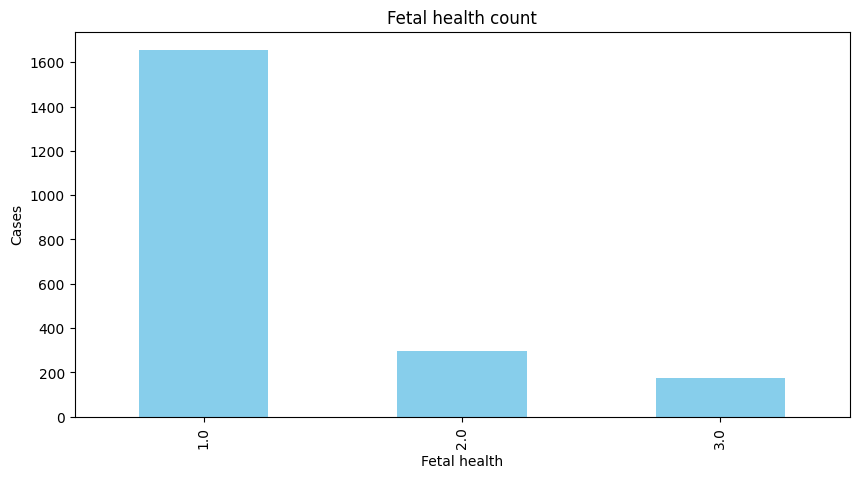

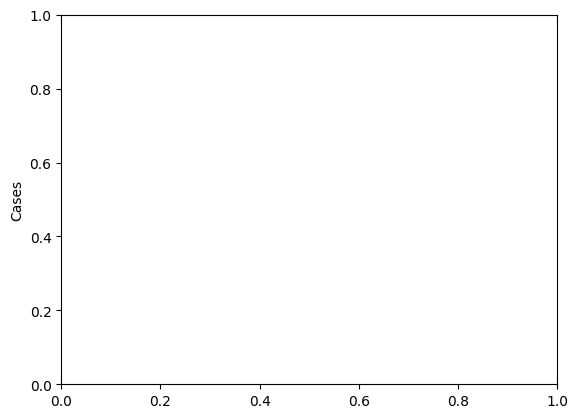

In [ ]:
from matplotlib import pyplot as plt
vis_fetal_health=fetal_data.fetal_health.value_counts().plot(figsize=(10,5),kind="bar",color="skyblue") #added color argument
plt.title("Fetal health count")
plt.xlabel("Fetal health")
plt.ylabel("Cases")
plt.show()
plt.ylabel("Cases")
plt.show()

<Axes: ylabel='count'>

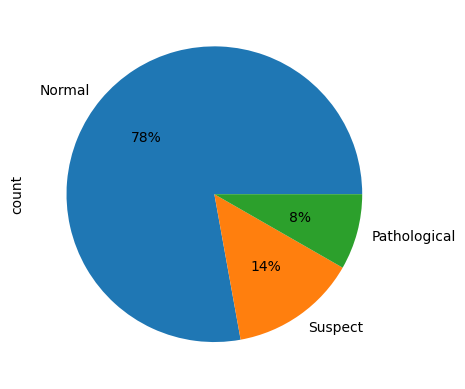

In [ ]:
fetal_data.fetal_health.value_counts().plot(kind='pie',autopct="%1.0f%%",labels=["Normal","Suspect","Pathological"])

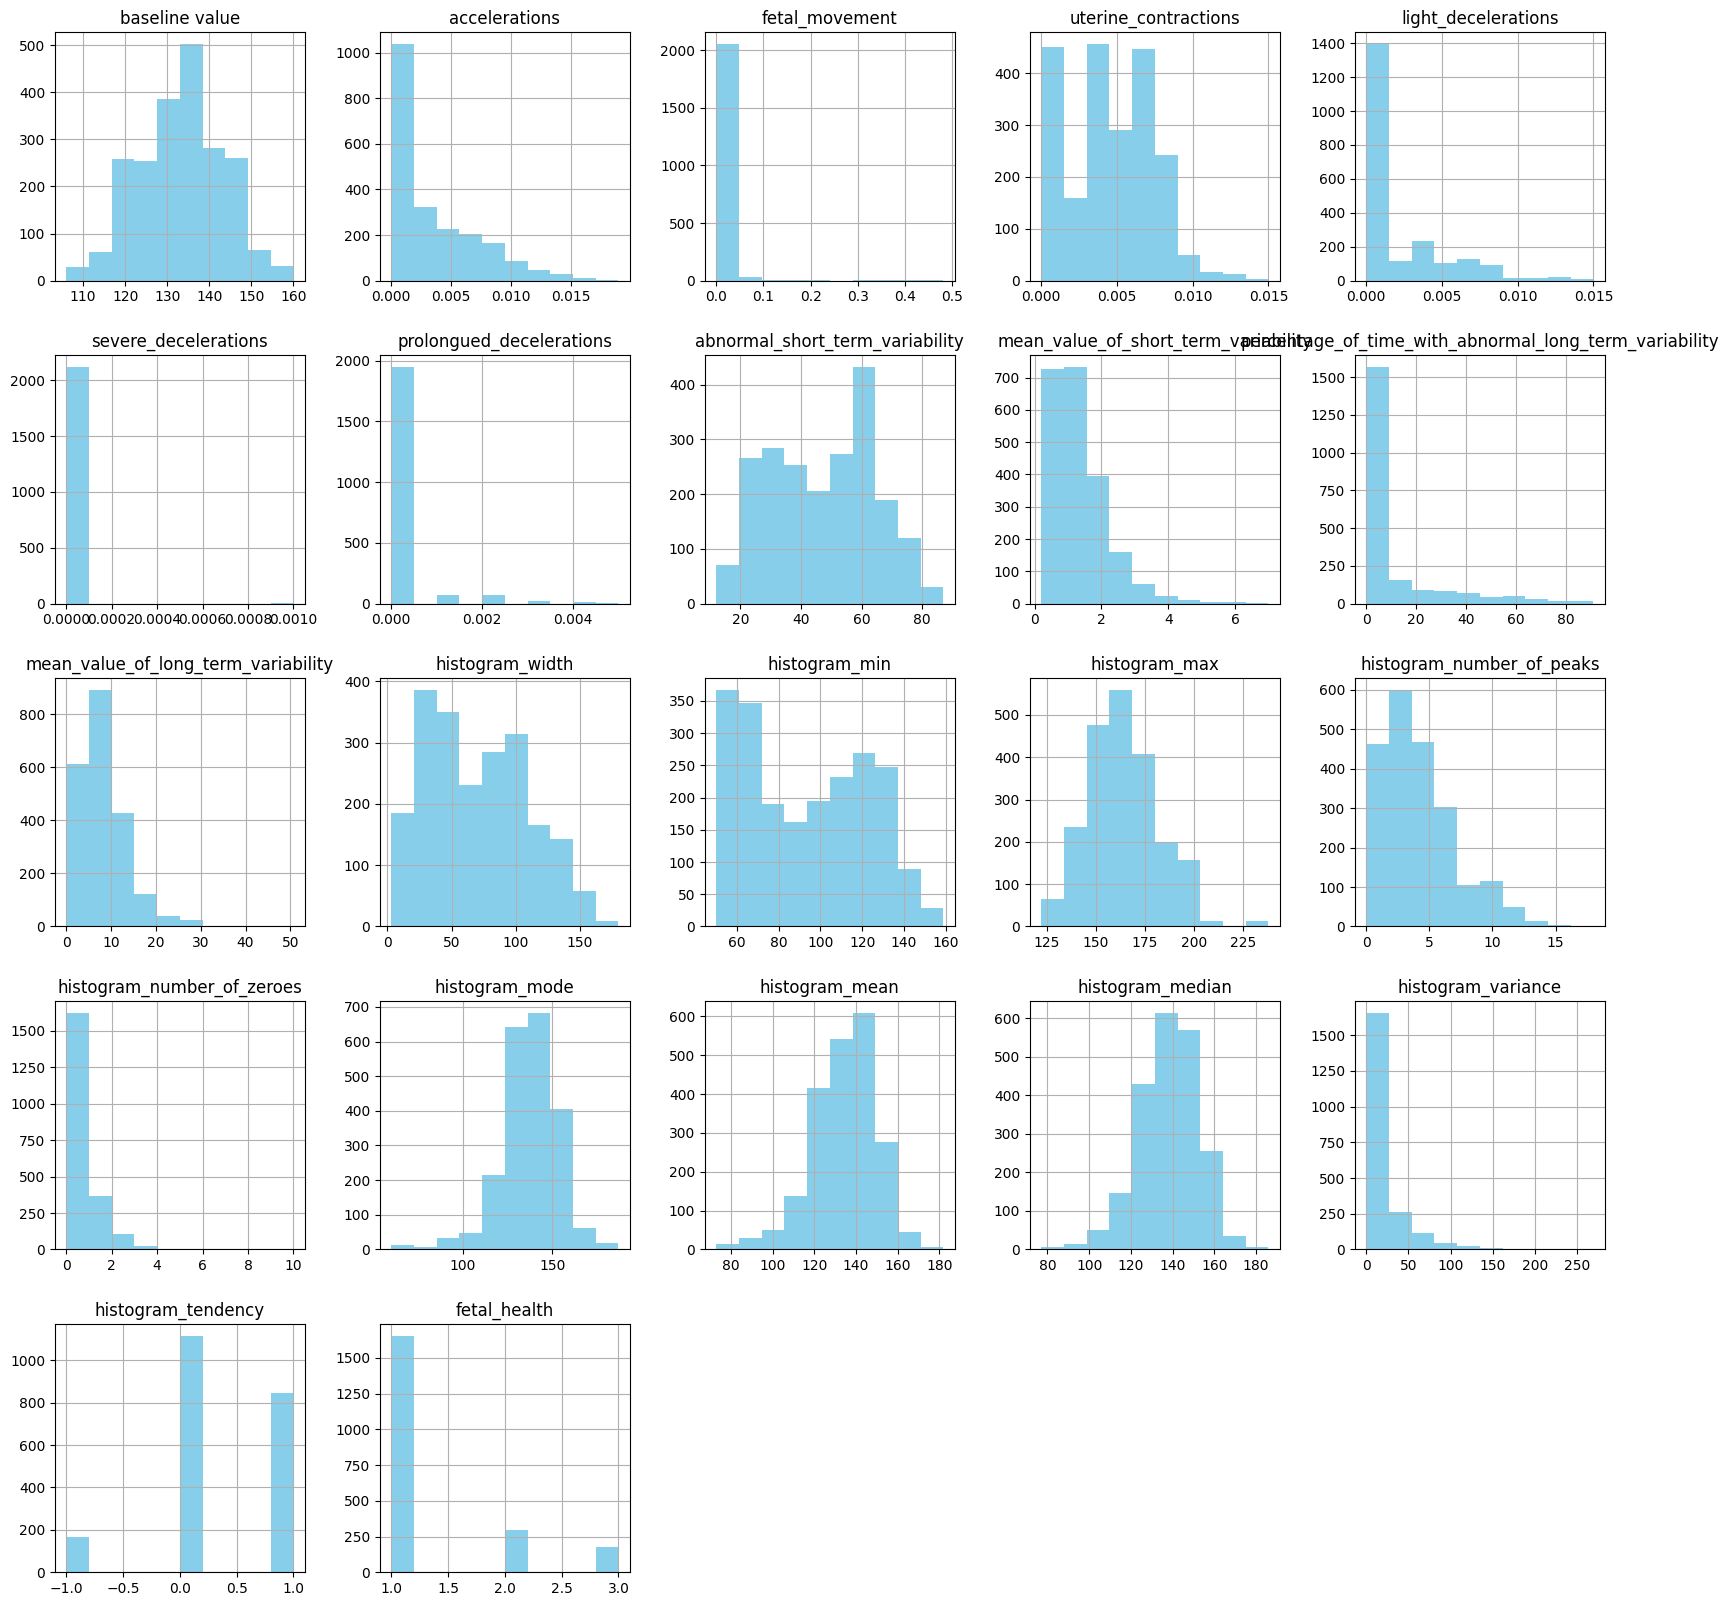

In [ ]:
data_hist_plot=fetal_data.hist(figsize=(20,20),color="skyblue")

In [ ]:
numeric_data=fetal_data.select_dtypes(exclude="object")
corr_matrix=numeric_data.corr()
corr_matrix

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
baseline value,1.000000,-0.080560,-0.033436,-0.146373,-0.159032,-0.053518,-0.104597,0.305570,-0.279607,0.285630,...,0.361619,0.275110,-0.113933,-0.004745,0.708993,0.723121,0.789246,-0.133938,0.293503,0.148151
accelerations,-0.080560,1.000000,0.048235,0.089674,-0.108615,-0.043018,-0.127749,-0.279577,0.207170,-0.373943,...,-0.154286,0.394147,0.190452,-0.006147,0.243610,0.270334,0.272849,0.125704,0.028420,-0.364066
fetal_movement,-0.033436,0.048235,1.000000,-0.068779,0.049228,-0.010976,0.265922,-0.103715,0.121314,-0.074096,...,-0.153917,0.099853,0.164654,-0.017749,-0.061192,-0.089671,-0.072329,0.179340,-0.001541,0.088010
uterine_contractions,-0.146373,0.089674,-0.068779,1.000000,0.285079,0.006788,0.077036,-0.232811,0.289679,-0.306608,...,-0.113323,0.122766,0.082693,0.057894,-0.104854,-0.187505,-0.140287,0.238582,-0.072314,-0.204894
light_decelerations,-0.159032,-0.108615,0.049228,0.285079,1.000000,0.107573,0.225611,-0.119152,0.562170,-0.271282,...,-0.553534,0.218043,0.397620,0.235296,-0.347233,-0.527354,-0.388586,0.564289,0.000072,0.058870
severe_decelerations,-0.053518,-0.043018,-0.010976,0.006788,0.107573,1.000000,0.012395,0.033949,0.034130,-0.030770,...,-0.071974,-0.021135,0.007024,0.043441,-0.215161,-0.158673,-0.160451,0.136421,-0.070483,0.131934
prolongued_decelerations,-0.104597,-0.127749,0.265922,0.077036,0.225611,0.012395,1.000000,0.046226,0.267011,-0.137333,...,-0.276764,0.120221,0.222860,0.056423,-0.436416,-0.488663,-0.444778,0.503301,-0.215405,0.484859
abnormal_short_term_variability,0.305570,-0.279577,-0.103715,-0.232811,-0.119152,0.033949,0.046226,1.000000,-0.430705,0.459413,...,0.275378,-0.111806,-0.167561,-0.149296,0.058363,0.074554,0.119960,-0.146434,-0.005748,0.471191
mean_value_of_short_term_variability,-0.279607,0.207170,0.121314,0.289679,0.562170,0.034130,0.267011,-0.430705,1.000000,-0.470259,...,-0.622569,0.409072,0.501430,0.266183,-0.307586,-0.445401,-0.336109,0.555852,-0.066140,-0.103382
percentage_of_time_with_abnormal_long_term_variability,0.285630,-0.373943,-0.074096,-0.306608,-0.271282,-0.030770,-0.137333,0.459413,-0.470259,1.000000,...,0.422834,-0.283183,-0.279301,-0.121784,0.165211,0.222321,0.186480,-0.281536,0.042481,0.426146


In [ ]:
pip install matplotlib

<Axes: >

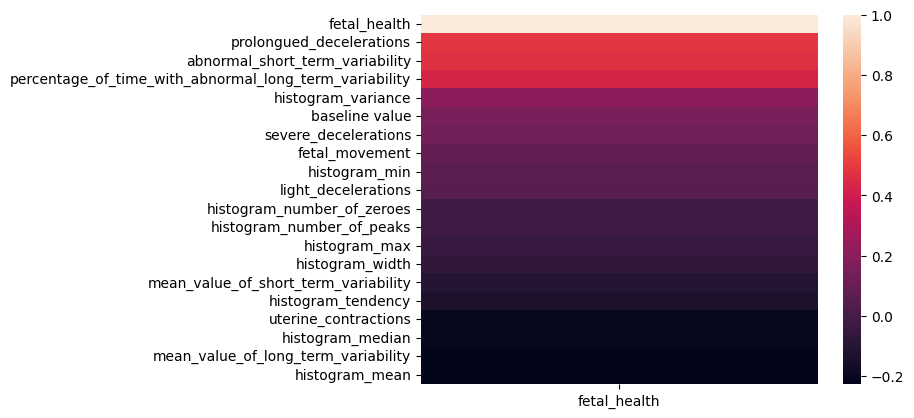

In [ ]:
import seaborn as sns
Num_feature = corr_matrix["fetal_health"].sort_values(ascending=False).head(20).to_frame()
cm = sns.heatmap(Num_feature)
cm

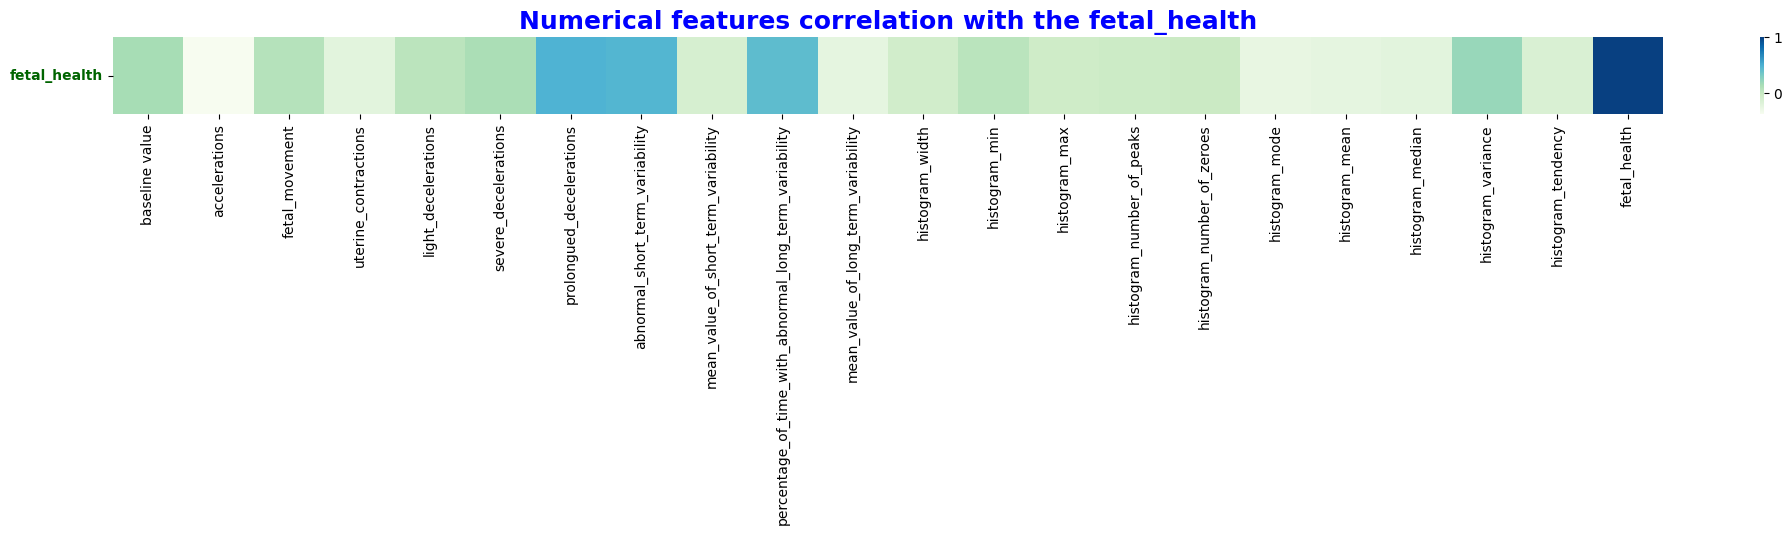

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_data = fetal_data.select_dtypes(exclude="object")
numeric_corr = numeric_data.corr()
f, ax = plt.subplots(figsize=(25, 1))
sns.heatmap(numeric_corr.sort_values(by=["fetal_health"], ascending=False).head(1), cmap="GnBu")
plt.title("Numerical features correlation with the fetal_health", weight="bold", fontsize=18, color="blue")
# Change 'rotations' to 'rotation' to fix the error
plt.yticks(weight="bold", color="darkgreen", rotation=0)

plt.show()

In [ ]:
import pandas as pd

# Load your dataset into a DataFrame (replace 'your_data.csv' with the actual path to your file)
df = pd.read_csv('fetal_health.csv')
corr_matrix = df.corr()
Num_feature = corr_matrix["fetal_health"].sort_values(ascending=False).head(20).to_frame()
Num_feature


,fetal_health
fetal_health,1.000000
prolongued_decelerations,0.484859
abnormal_short_term_variability,0.471191
percentage_of_time_with_abnormal_long_term_variability,0.426146
histogram_variance,0.206630
baseline value,0.148151
severe_decelerations,0.131934
fetal_movement,0.088010
histogram_min,0.063175
light_decelerations,0.058870


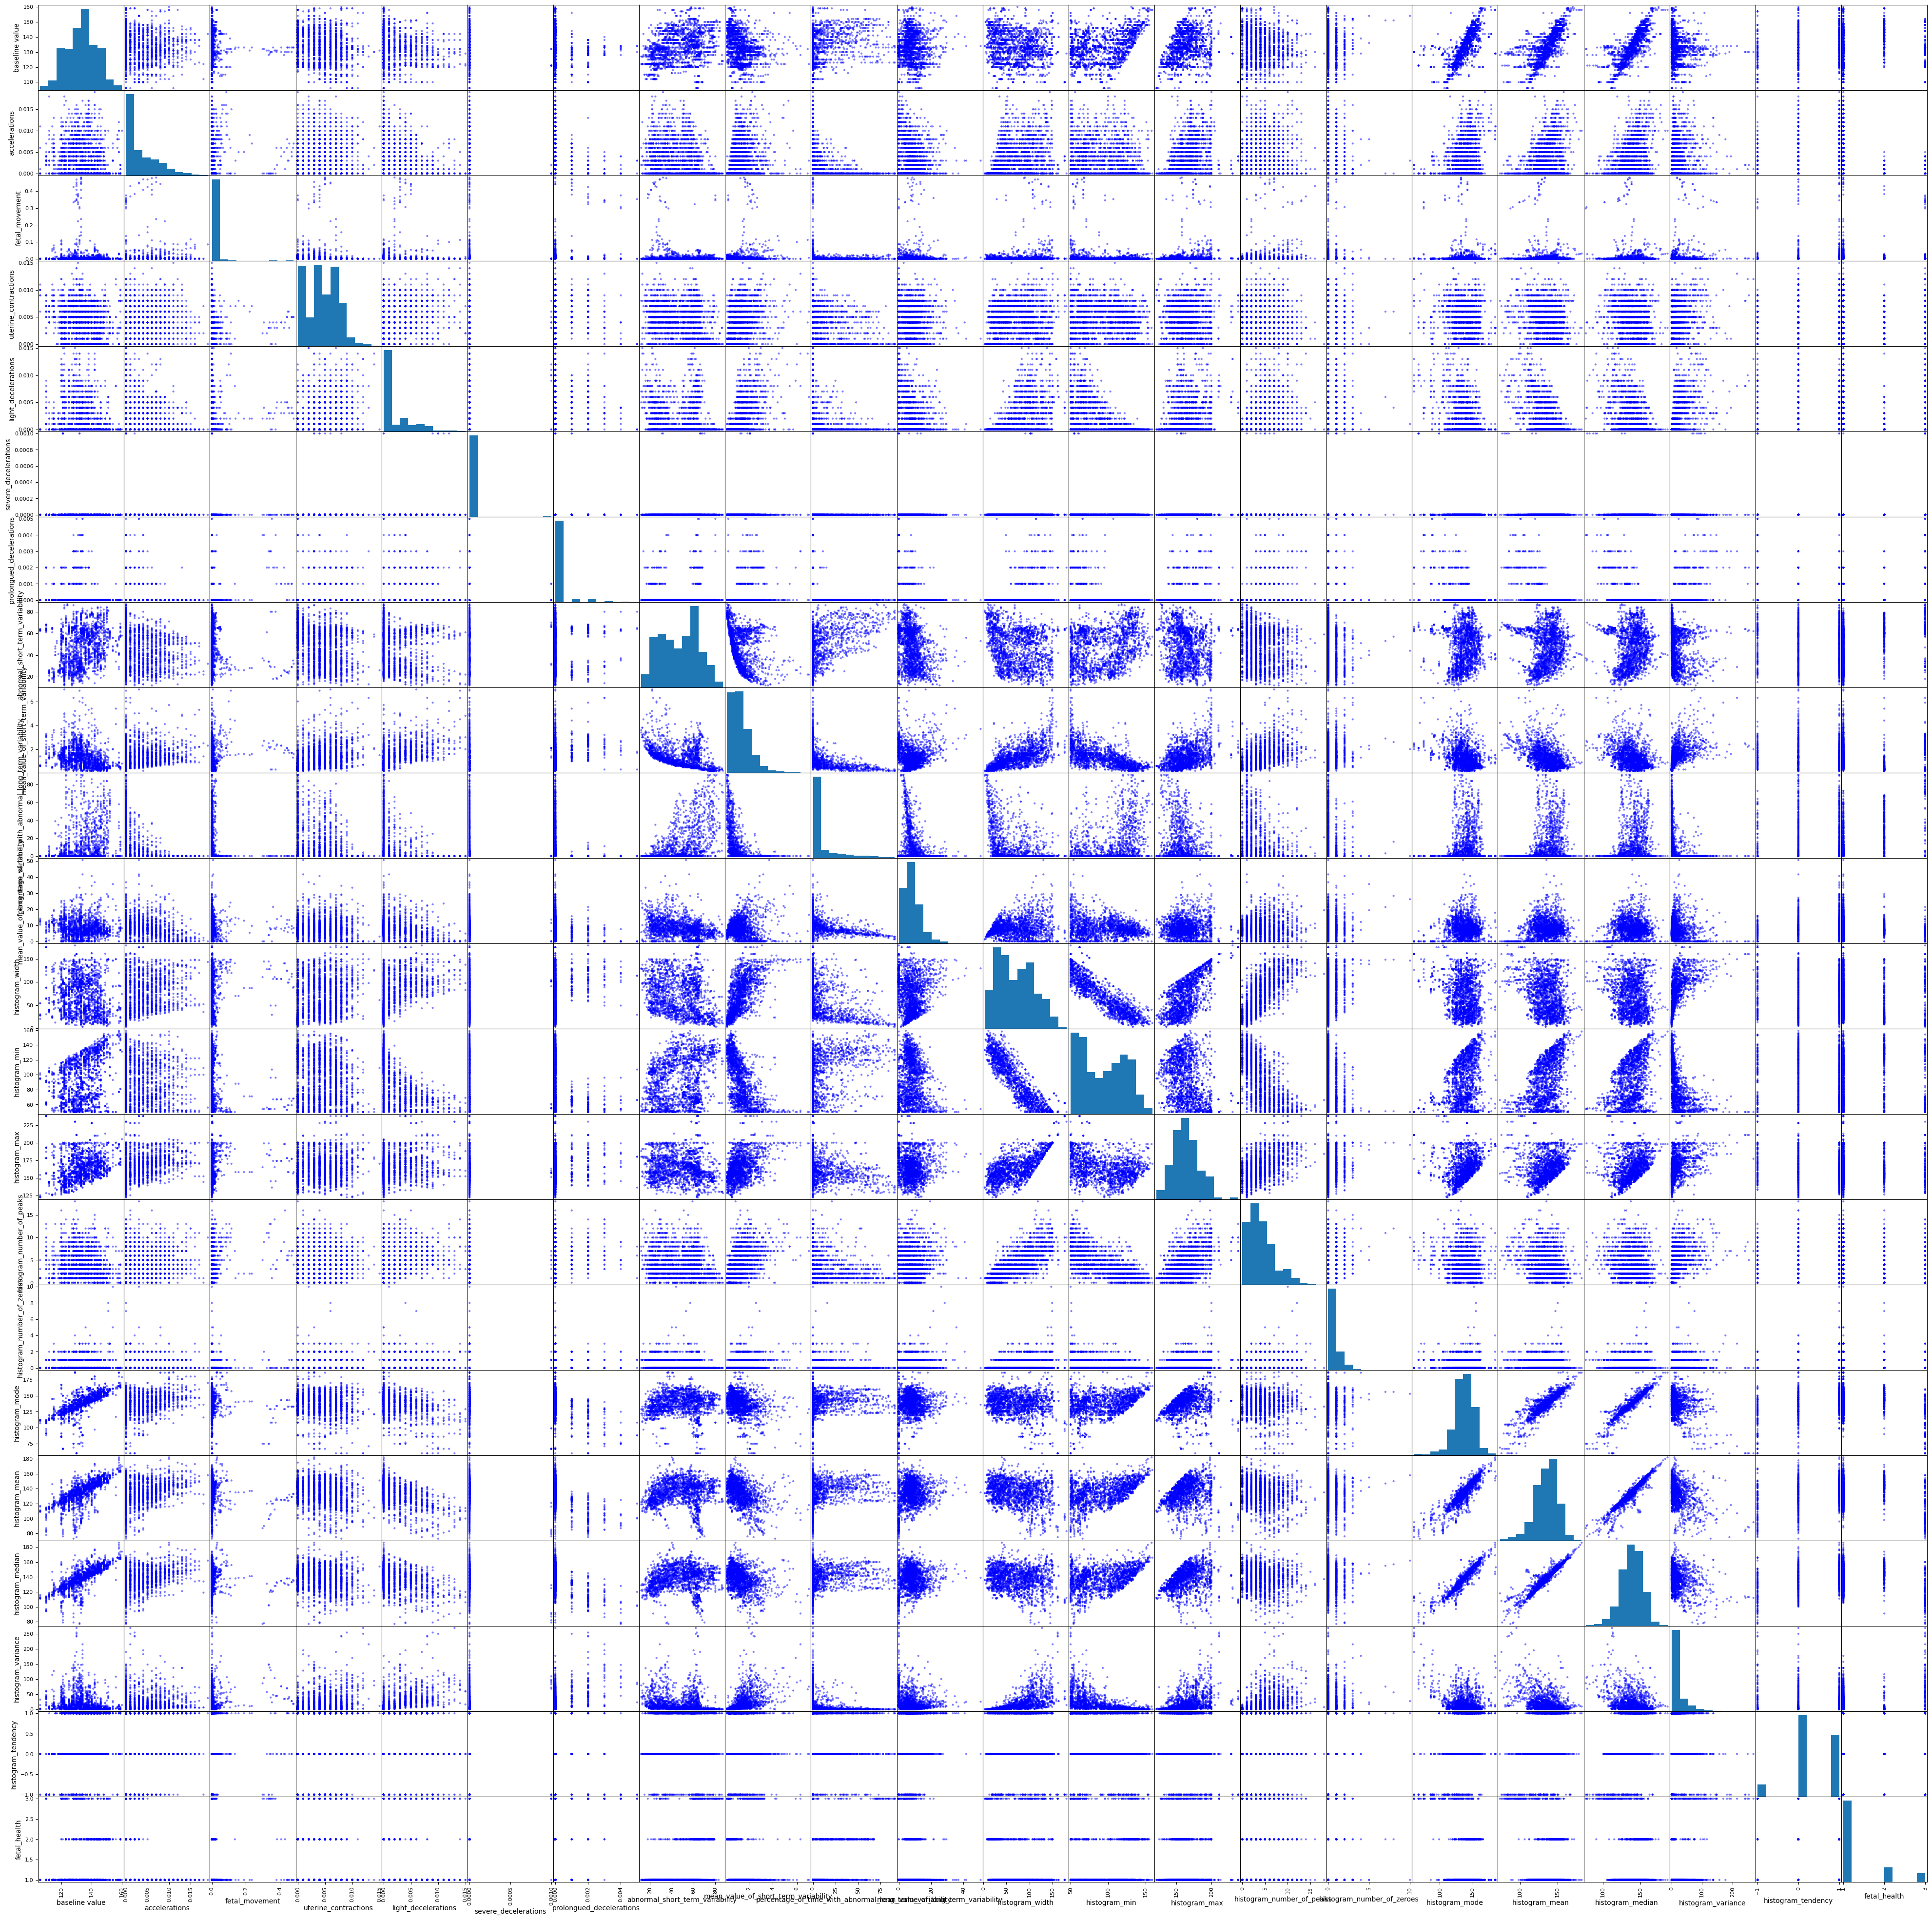

In [ ]:
from pandas.plotting import scatter_matrix
import pandas as pd

# Assuming 'df' is your DataFrame as loaded in previous code
data = pd.read_csv('fetal_health.csv')  # Load your dataset, replace 'your_data.csv' with your file
scatterMatrix = scatter_matrix(data, figsize=(50, 50), color="blue")

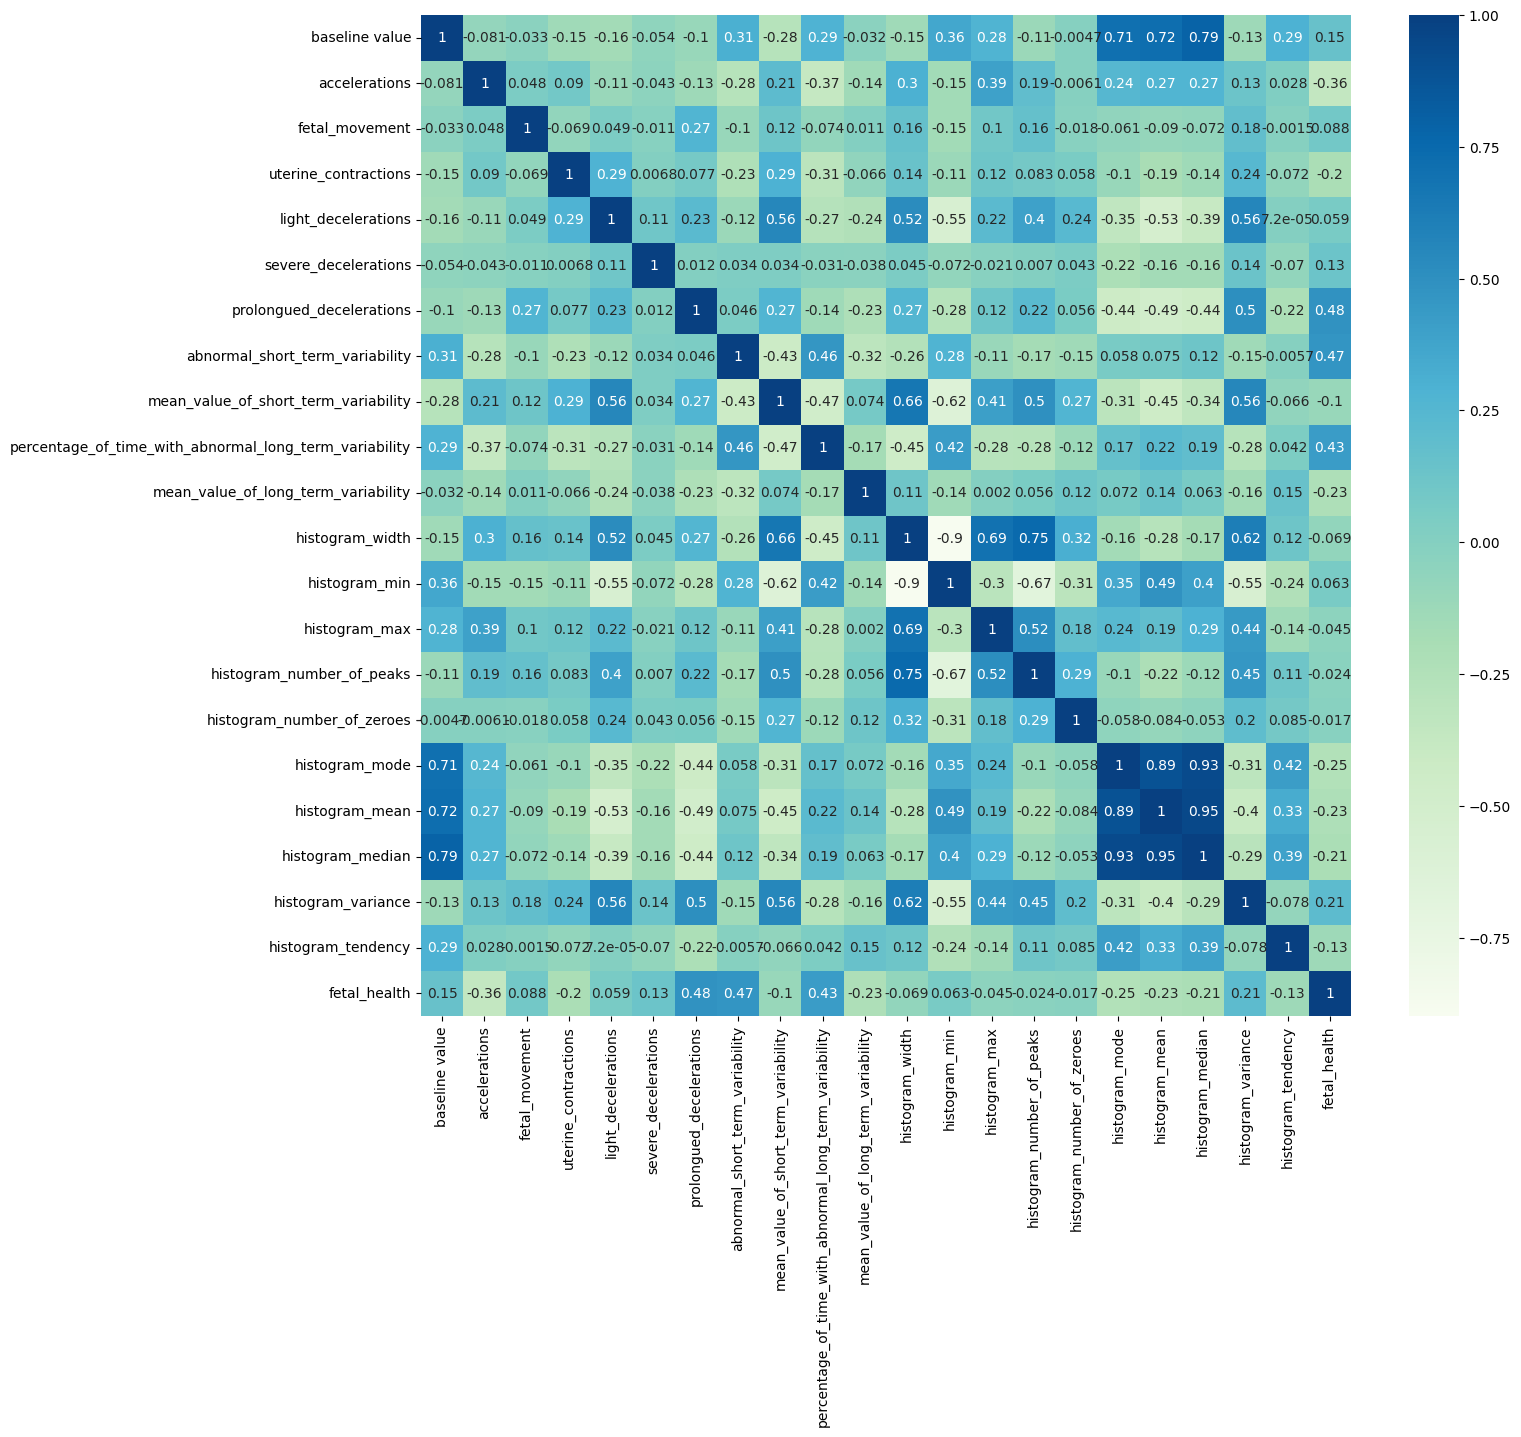

In [ ]:
plt.figure(figsize=(15,13))
p=sns.heatmap(corr_matrix,annot=True,cmap = "GnBu")

In [ ]:
!pip install scikit-learn
import pandas as pd
from sklearn.preprocessing import StandardScaler  # Import StandardScaler

# Assuming 'fetal_health.csv' contains your data
fetal_data = pd.read_csv('fetal_health.csv') # Load your data into a DataFrame called fetal_data.

columns = ['baseline value','accelerations','fetal_movement','uterine_contractions','ligth_decelerations','severe_decelerations','prolongued_decelerations','abnormal_short_term_variability','mean_value_of_short_term_variability','percentage_of_time_with_abnormal_long_term_variability','mean_value_of_long_term_variability','histogram_width','histogram_min','histogram_max','histogram_number_of _peaks','histogram_number_of_zeroes','histogram_mode','histogram_mean','histogram_median','histogram_variance','histogram_tendency']
scale_X = StandardScaler()
X = pd.DataFrame(scale_X.fit_transform(fetal_data.drop(["fetal_health"],axis = 1),),columns = columns)


In [ ]:
X.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,ligth_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_width,histogram_min,histogram_max,histogram_number_of _peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency
0,-1.352220,-0.822388,-0.20321,-1.482465,-0.638438,-0.057476,-0.268754,1.513190,-0.943095,1.802542,...,-0.165507,-1.068562,-2.119592,-0.701397,-0.458444,-1.065614,0.153270,-1.181642,1.870569,1.112980
1,-0.132526,0.730133,-0.20321,0.554627,0.375243,-0.057476,-0.268754,-1.744751,0.868841,-0.535361,...,1.529124,-0.865539,1.893794,0.655137,0.958201,0.216638,0.089126,0.132038,-0.234998,-0.524526
2,-0.030884,-0.046128,-0.20321,1.233657,0.375243,-0.057476,-0.268754,-1.802928,0.868841,-0.535361,...,1.529124,-0.865539,1.893794,0.316003,0.958201,0.216638,0.024982,-0.006244,-0.200481,-0.524526
3,0.070757,-0.046128,-0.20321,1.233657,0.375243,-0.057476,-0.268754,-1.802928,1.208579,-0.535361,...,1.195333,-1.373097,0.333033,2.350804,-0.458444,-0.027600,-0.039162,-0.075385,-0.200481,1.112980
4,-0.132526,0.988886,-0.20321,1.233657,-0.638438,-0.057476,-0.268754,-1.802928,1.208579,-0.535361,...,1.195333,-1.373097,0.333033,1.672537,-0.458444,-0.027600,0.089126,-0.006244,-0.269516,1.112980


In [ ]:
y=fetal_data["fetal_health"]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
!pip install scikit-learn
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split # Import train_test_split

# Assuming 'fetal_health.csv' contains your data
fetal_data = pd.read_csv('fetal_health.csv') # Load your data into a DataFrame called fetal_data.

columns = ['baseline value','accelerations','fetal_movement','uterine_contractions','ligth_decelerations','severe_decelerations','prolongued_decelerations','abnormal_short_term_variability','mean_value_of_short_term_variability','percentage_of_time_with_abnormal_long_term_variability','mean_value_of_long_term_variability','histogram_width','histogram_min','histogram_max','histogram_number_of _peaks','histogram_number_of_zeroes','histogram_mode','histogram_mean','histogram_median','histogram_variance','histogram_tendency']
scale_X = StandardScaler()
X = pd.DataFrame(scale_X.fit_transform(fetal_data.drop(["fetal_health"],axis = 1),),columns = columns)

y = fetal_data["fetal_health"] # Define y before splitting

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.shape, X_test.shape, y_train.shape, y_test.shape # Now this line should work

((1700, 21), (426, 21), (1700,), (426,))

In [ ]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1700, 21), (426, 21), (1700,), (426,))

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier


In [ ]:
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix


In [ ]:
log_reg_model = LogisticRegression()
log_reg_model.fit(X_train, y_train)

LogisticRegression()

In [ ]:
y_pred = log_reg_model.predict(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Load a dataset for example purposes
data = load_iris()
X = data.data
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the logistic regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)  # Ensure y_pred is defined here

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of logistic Regression = {round(accuracy * 100, 2)}%")


Accuracy of logistic Regression = 100.0%


In [ ]:
from sklearn.model_selection import cross_val_score,StratifieldKFold

In [ ]:
cv_method = StratifiedKFold(n_splits=3)


In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Load a dataset for example purposes
data = load_iris()
X = data.data
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the logistic regression model
log_reg_model = LogisticRegression() # Initialize log_reg_model
log_reg_model.fit(X_train, y_train)

# Make predictions
y_pred = log_reg_model.predict(X_test)  # Ensure y_pred is defined here

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of logistic Regression = {round(accuracy * 100, 2)}%")

cv_method = StratifiedKFold(n_splits=3)

cv_score = cross_val_score(log_reg_model,
                            X_train, y_train,
                            cv=cv_method,
                            n_jobs=2,
                            scoring="accuracy")
print(f"Scores(Corss validate) for Logistic Regression model:\n{cv_score}")
print(f"CrossValMeans:{round(cv_score.mean(),3)*100}%")
print(f"CrossValStandad Deviation:{round(cv_score.std(),3)}")
#The following lines were incorrectly indented and seemingly duplicated a part of previous code.
#They have been removed and the variable in the print statements have been adjusted
#to reflect the intended output.


Accuracy of logistic Regression = 100.0%
Scores(Corss validate) for Logistic Regression model:
[1.    0.925 0.975]
CrossValMeans:96.7%
CrossValStandad Deviation:0.031


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression # Import LogisticRegression here

param_grid = {'C': [0.1, 1, 10]}  # Example parameter grid
GridSearchCV_LR = GridSearchCV(estimator=LogisticRegression(), param_grid=param_grid, cv=5)

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV # Import GridSearchCV here
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
GridSerachCV_LR=GridSearchCV(estimator=log_reg_model,
                             param_grid=params_LR,
                             cv=cv_method,
                             verbose=1,
                             n_jobs=2,
                             scoring="accuracy",
                             return_train_score=True
)

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV # Import GridSearchCV here
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Load a dataset for example purposes
data = load_iris()
X = data.data
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the logistic regression model
log_reg_model = LogisticRegression() # Initialize log_reg_model
log_reg_model.fit(X_train, y_train)

#Now that log_reg_model is defined, we can safely use it within GridSearchCV
params_LR = {'C': [0.1, 1, 10]}  # Example parameter grid

# Define cv_method before using it in GridSearchCV
cv_method = StratifiedKFold(n_splits=3)

# Correct the variable name here to 'GridSearchCV_LR'
GridSearchCV_LR = GridSearchCV(estimator=log_reg_model,
                             param_grid=params_LR,
                             cv=cv_method,
                             verbose=1,
                             n_jobs=2,
                             scoring="accuracy",
                             return_train_score=True
)


In [ ]:
params_LR={"tol":[0.0001,0.0002,0.0003],
           "C":[0.01,0.1,1,10,100], # Changed 'c' to 'C'
           "intercept_scaling":[1,2,3,4]
}

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Load a dataset
data = load_iris()
X = data.data
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define the parameter grid
params_LR = {
    "tol": [0.0001, 0.0002, 0.0003],
    "C": [0.01, 0.1, 1, 10, 100],
    "intercept_scaling": [1, 2, 3, 4]
}

# Initialize the model
model = LogisticRegression()

# Set up GridSearchCV
grid_search = GridSearchCV(estimator=model, param_grid=params_LR, cv=5, n_jobs=-1)

# Fit the grid search to the data
grid_search.fit(X_train, y_train)

# Print best parameters and score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)


Best parameters: {'C': 1, 'intercept_scaling': 1, 'tol': 0.0001}
Best score: 0.9666666666666666


In [ ]:
best_estimator_LR = GridSearchCV_LR.best_estimator_LRprint(f"Best estimator for LR model:\n{best_estimator_LR}")

NameError: name 'GridSearchCV_LR' is not defined

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Define the Logistic Regression model
log_reg_model = LogisticRegression() # Define log_reg_model
# Define the cross-validation method
cv_method = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # Define cv_method


# Define the parameter grid
params_LR = {
    "tol": [0.0001, 0.0002, 0.0003],
    "C": [0.01, 0.1, 1, 10, 100],
    "intercept_scaling": [1, 2, 3, 4]
}

# Initialize GridSearchCV with the correct variable name
GridSearchCV_LR = GridSearchCV(estimator=log_reg_model,
                             param_grid=params_LR,
                             cv=cv_method,
                             verbose=1,
                             n_jobs=2,
                             scoring="accuracy",
                             return_train_score=True
)

# Fit the model
GridSearchCV_LR.fit(X_train, y_train)

# Get the best estimator and print its details
best_estimator_LR = GridSearchCV_LR.best_estimator_ # Access the best estimator using best_estimator_
print(f"Best estimator for LR model:\n{best_estimator_LR}") # Print the best estimator



Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best estimator for LR model:
LogisticRegression(C=1)


In [ ]:
best_params_LR=GridSearchCV_LR.best_params_
print(f"Best parameters for Logistic Regression model:\n{best_params_LR}")


Best parameters for Logistic Regression model:
{'C': 1, 'intercept_scaling': 1, 'tol': 0.0001}


In [ ]:
print(f"Best score for LR model: {round(GridSearchCV_LR.best_score_,3)*100}%")

AttributeError: 'GridSearchCV' object has no attribute 'best_score_'

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Define the Logistic Regression model
log_reg_model = LogisticRegression() # Define log_reg_model
# Define the cross-validation method
cv_method = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # Define cv_method


# Define the parameter grid
params_LR = {
    "tol": [0.0001, 0.0002, 0.0003],
    "C": [0.01, 0.1, 1, 10, 100],
    "intercept_scaling": [1, 2, 3, 4]
}

# Initialize GridSearchCV with the correct variable name and refit=True
GridSearchCV_LR = GridSearchCV(estimator=log_reg_model,
                             param_grid=params_LR,
                             cv=cv_method,
                             verbose=1,
                             n_jobs=2,
                             scoring="accuracy",
                             return_train_score=True,
                             refit=True # Ensure refit is set to True
)

# Fit the model
GridSearchCV_LR.fit(X_train, y_train)

# Get the best estimator and print its details
best_estimator_LR = GridSearchCV_LR.best_estimator_ # Access the best estimator using best_estimator_
print(f"Best estimator for LR model:\n{best_estimator_LR}") # Print the best estimator


Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best estimator for LR model:
LogisticRegression(C=1)


In [ ]:
print(f"Best score for LR model: {round(GridSearchCV_LR.best_score_,3)*100}%")

Best score for LR model: 95.0%


In [ ]:
from sklearn.metrics import classification_report # Import the classification_report function
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Load the iris dataset
iris = load_iris()
X, y = iris.data, iris.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Assuming GridSearchCV_LR is already fitted (from previous code)
# Get predictions on the test set
y_pred_lr = GridSearchCV_LR.predict(X_test)  # Assign predictions to y_pred_lr

print("Classification Report")
print(classification_report(y_test, y_pred_lr)) # Use the correct function name: classification_report

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix # Import confusion_matrix along with classification_report
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
print("confusion Matrix:")
print(confusion_matrix(y_test,y_pred_lr))

confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


[Text(0.5, 0, 'Normal'), Text(1.5, 0, 'Suspect'), Text(2.5, 0, 'Pathological')]

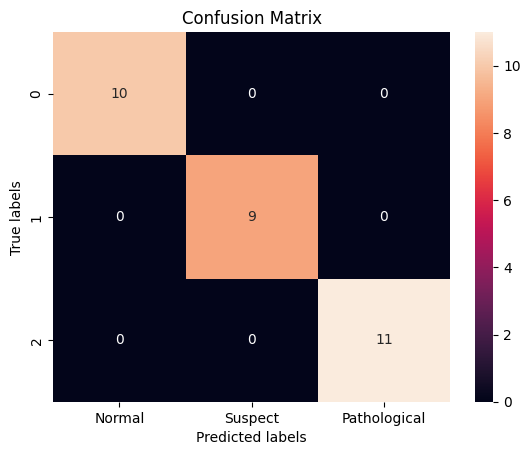

In [ ]:
import matplotlib.pyplot as plt  # Import the pyplot module and assign it the alias 'plt'
import seaborn as sns
from sklearn.metrics import confusion_matrix

ax = plt.subplot()
# Replace pred_logistic_regression with y_pred_lr which contains the predictions
cf = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cf, annot=True, fmt='0.3g')
ax.set_xlabel('Predicted labels')
ax.set_ylabel('True labels')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(['Normal', 'Suspect', 'Pathological'])



In [ ]:
from sklearn.neighbors import KNeighborsClassifier # Import the KNeighborsClassifier class

knn = KNeighborsClassifier()
knn_mod = knn.fit(X_train, y_train)
print(f"Baseline K-Nearest Neighbors: {round(knn_mod.score(X_test, y_test), 3) * 100}%")  # Use X_test instead of x_test
pred_knn = knn_mod.predict(X_test)

Baseline K-Nearest Neighbors: 100.0%


In [ ]:
cv_method=StratifiedKFold(n_splits=3)
scores_knn=cross_val_score(knn,X_train,y_train,cv=cv_method,n_jobs=2,scoring="accuracy")
cv_method=StratifiedKFold(n_splits=3)
scores_knn=cross_val_score(knn,X_train,y_train,cv=cv_method,n_jobs=2,scoring="accuracy")
print(f"Scores(Cross validate) for K- Nearest Neighbors model:\n{scores_knn}")
print(f"CrossValMeans:{round(scores_knn.mean(),2)*100}%")
print(f"CrossValStandad Deviation:{round(scores_knn.std(),3)}")

Scores(Cross validate) for K- Nearest Neighbors model:
[0.925 0.9   0.975]
CrossValMeans:93.0%
CrossValStandad Deviation:0.031


In [ ]:
params_knn={"leaf_size": list(range(1,30)),"n_neighbors":list(range(1,21)),"p":[1,2]}

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

# ... (assuming params_knn and cv_method are defined as in your previous cells)

# Fix: Remove 'estimator+' and just pass KNeighborsClassifier() directly
GridSearchCV_knn = GridSearchCV(KNeighborsClassifier(),
                                 cv=cv_method,
                                 param_grid=params_knn,
                                 verbose=1,
                                 n_jobs=1,
                                 scoring="accuracy", # Fix: scoring should be a string
                                 return_train_score=True) # Fix: This is a separate parameter

In [ ]:
GridSearchCV_knn.fit(X_train, y_train);

Fitting 3 folds for each of 1160 candidates, totalling 3480 fits


In [ ]:
best_estimator_knn=GridSearchCV_knn.best_estimator_
print(f"Best estimator for KNN model:\n{best_estimator_knn}")

Best estimator for KNN model:
KNeighborsClassifier(leaf_size=1, n_neighbors=3, p=1)


In [ ]:
best_params_knn=GridSearchCV_knn.best_params_
print(f"Best parameters for KNN model:\n{best_params_knn}")

Best parameters for KNN model:
{'leaf_size': 1, 'n_neighbors': 3, 'p': 1}


In [ ]:
best_scores_knn=GridSearchCV_knn.best_score_
print(f"Best score for GNB model:{round(best_scores_knn,3)*100}%")

Best score for GNB model:95.8%


In [ ]:
print("Classification Report")
print(classification_report(y_test, pred_knn))

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [ ]:
print("confusion Matrix:")
print(confusion_matrix(y_test,pred_knn))

confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


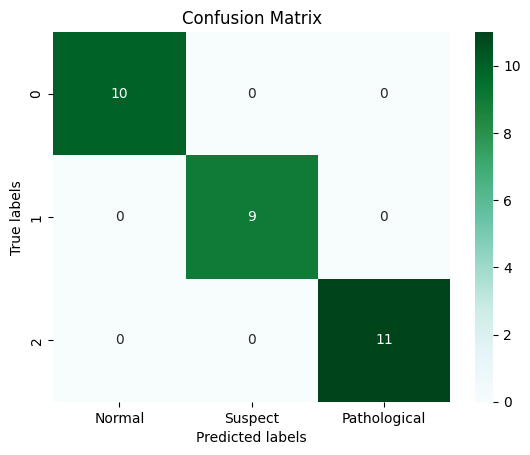

In [ ]:
ax=plt.subplot()
sns.heatmap(confusion_matrix(y_test,pred_knn),annot=True,ax=ax,cmap="BuGn"); # Changed annot+True to annot=True
ax.set_xlabel("Predicted labels");
ax.set_ylabel("True labels");
ax.set_title("Confusion Matrix");
ax.xaxis.set_ticklabels(["Normal","Suspect","Pathological"]);

In [ ]:
!pip install scikit-learn  # Install scikit-learn if you haven't already
from sklearn.ensemble import RandomForestClassifier # Import RandomForestClassifier

random_forest=RandomForestClassifier()
random_forest_mod=random_forest.fit(X_train,y_train)
print(f"Baseline Random Forest: {round(random_forest_mod.score(X_test,y_test),3)*100}%")
pred_random_forest=random_forest_mod.predict(X_test)

Baseline Random Forest: 100.0%


In [ ]:
scores_RF = cross_val_score(random_forest, X_train, y_train, cv=cv_method, n_jobs=2, scoring="accuracy")  # Changed y_traiin to y_train
scores_RF = cross_val_score(random_forest, X_train, y_train, cv=cv_method, n_jobs=2, scoring="accuracy")  # Changed y_traiin to y_train
print(f"Scores(Cross validate) for Random Forest model:\n{scores_RF}")
print(f"CrossValMeans:{round(scores_RF.mean(), 2) * 100}%")
print(f"CrossValStandad Deviation:{round(scores_RF.std(), 3)}")


Scores(Cross validate) for Random Forest model:
[0.975 0.9   0.975]
CrossValMeans:95.0%
CrossValStandad Deviation:0.035


In [ ]:
params_RF={"min_samples_split":[2,6,20],"min_samples_leaf":[1,4,16],"n_estimators":[100,200,300,400],"criterion":["gini"]
           }

In [ ]:
GridSearchCV_RF=GridSearchCV(estimator=random_forest,
                             param_grid=params_RF,
                             cv=cv_method,
                             verbose=1,
                             n_jobs=2,
                             scoring="accuracy",
                             return_train_score=True
)

In [ ]:
GridSearchCV_RF.fit(X_train,y_train)

Fitting 3 folds for each of 36 candidates, totalling 108 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=None, shuffle=False),
             estimator=RandomForestClassifier(), n_jobs=2,
             param_grid={'criterion': ['gini'], 'min_samples_leaf': [1, 4, 16],
                         'min_samples_split': [2, 6, 20],
                         'n_estimators': [100, 200, 300, 400]},
             return_train_score=True, scoring='accuracy', verbose=1)

In [ ]:
best_estimator_RF=GridSearchCV_RF.best_estimator_
print(f"Best estimator for RF model:\n{best_estimator_RF}")

Best estimator for RF model:
RandomForestClassifier()


In [ ]:
best_params_RF=GridSearchCV_RF.best_params_
print(f"Best parameters for RF model:\n{best_params_RF}")

Best parameters for RF model:
{'criterion': 'gini', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [ ]:
best_score_RF=GridSearchCV_RF.best_score_
print(f"Best score for RF model:{round(best_score_RF,3)*100}%")

Best score for RF model:95.8%


In [ ]:
print("Classification Report")
print(classification_report(y_test, pred_random_forest))

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [ ]:
print("confusion Matrix:")
print(confusion_matrix(y_test,pred_random_forest))

confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


[Text(0.5, 0, 'Normal'), Text(1.5, 0, 'Suspect'), Text(2.5, 0, 'Pathological')]

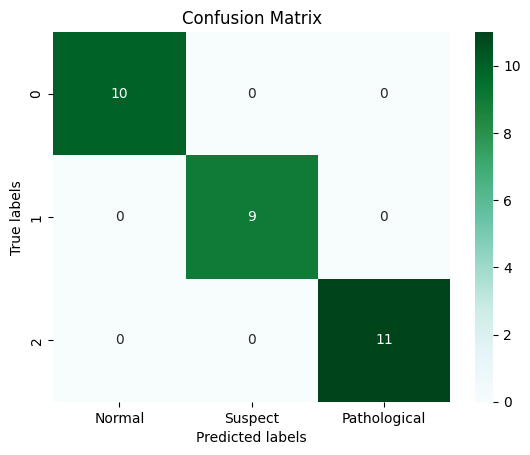

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

ax = plt.subplot()
sns.heatmap(confusion_matrix(y_test, pred_random_forest), annot=True, ax=ax, cmap="BuGn")
ax.set_xlabel("Predicted labels") # Removed extra indentation
ax.set_ylabel("True labels") # Removed extra indentation
ax.set_title("Confusion Matrix") # Removed extra indentation
ax.xaxis.set_ticklabels(["Normal", "Suspect", "Pathological"]) # Removed extra indentation

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier # Importing the GradientBoostingClassifier

gbc=GradientBoostingClassifier()
gb_mod=gbc.fit(X_train,y_train) # Changed gb_mod to gbc
print(f"Baseline gradient boosting classifier: {round (gb_mod.score(X_test,y_test),3)*100}%")
pred_gbc=gb_mod.predict(X_test)

Baseline gradient boosting classifier: 100.0%


In [ ]:
scores_GBC=cross_val_score(gbc,X_train,y_train,cv=cv_method,n_jobs=2,scoring="accuracy")
scores_GBC=cross_val_score(gbc,X_train,y_train,cv=cv_method,n_jobs=2,scoring="accuracy")
print(f"Scores(Cross validate) for Gradient Boosting Classifier model:\n{scores_GBC}")
print(f"CrossValMeans:{round(scores_GBC.mean(),3)*100}%")
print(f"CrossValStandad Deviation:{round(scores_GBC.std(),3)}")

Scores(Cross validate) for Gradient Boosting Classifier model:
[0.95 0.9  0.95]
CrossValMeans:93.30000000000001%
CrossValStandad Deviation:0.024


In [ ]:
params_GBC={"loss":["deviance"],"learning_rate":[0.05,0.075,0.1,0.25,0.75,1],"n_estimators":[250,500],"max_depth":[3,5,8]}

In [ ]:
GridSearchCV_GBC=GridSearchCV(estimator=gbc,
                             param_grid=params_GBC,
                             cv=cv_method,
                             verbose=1,
                             n_jobs=2,
                              scoring="accuracy",
                             return_train_score=True
)

In [ ]:
params_GBC={"loss":["log_loss"],"learning_rate":[0.05,0.075,0.1,0.25,0.75,1],"n_estimators":[250,500],"max_depth":[3,5,8]} # Changed the "loss" parameter from "deviance" to "log_loss"


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

# Assuming gbc is your GradientBoostingClassifier instance
gbc = GradientBoostingClassifier()

# Assuming cv_method is your cross-validation method
cv_method = 5  # Example: 5-fold cross-validation

# Define the updated parameter grid (use either "log_loss" or "exponential")
params_GBC={"loss":["log_loss"],"learning_rate":[0.05,0.075,0.1,0.25,0.75,1],"n_estimators":[250,500],"max_depth":[3,5,8]}

# Re-initialize GridSearchCV_GBC with the updated params_GBC
GridSearchCV_GBC=GridSearchCV(estimator=gbc,
                             param_grid=params_GBC,
                             cv=cv_method,
                             verbose=1,
                             n_jobs=2,
                             scoring="accuracy",
                             return_train_score=True
)
# Re-fit the model
GridSearchCV_GBC.fit(X_train,y_train)

# Now you can access best_estimator_
best_estimator_GBC=GridSearchCV_GBC.best_estimator_
print(f"Best estimator for GBC model:\n{best_estimator_GBC}")


Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best estimator for GBC model:
GradientBoostingClassifier(learning_rate=0.05, max_depth=8, n_estimators=250)


In [ ]:
best_estimator_GBC=GridSearchCV_GBC.best_estimator_
print(f"Best estimator for GBC model:\n{best_estimator_GBC}")
#

Best estimator for GBC model:
GradientBoostingClassifier(learning_rate=0.05, max_depth=8, n_estimators=250)


In [ ]:
best_params_GBC=GridSearchCV_GBC.best_params_
print(f"Best parameters for GBC model:\n{best_params_GBC}")
#

Best parameters for GBC model:
{'learning_rate': 0.05, 'loss': 'log_loss', 'max_depth': 8, 'n_estimators': 250}


In [ ]:
best_score_GBC=GridSearchCV_GBC.best_score_
print(f"Best score for GBC model:{round(best_score_GBC,3)*100}%")

Best score for GBC model:95.0%


In [ ]:
print("Classification Report")
print(classification_report(y_test, pred_gbc))

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [ ]:
print("confusion Matrix:")
print(confusion_matrix(y_test,pred_gbc))

confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


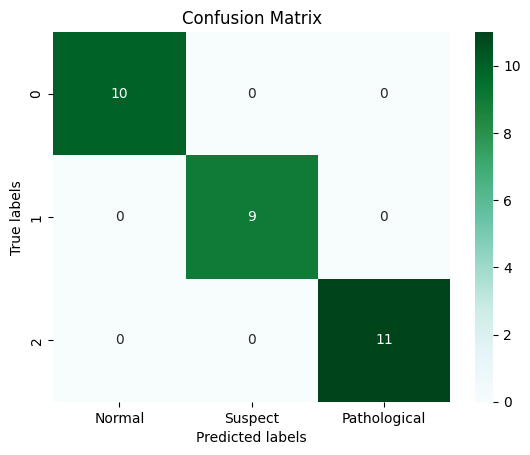

In [ ]:
ax=plt.subplot()
sns.heatmap(confusion_matrix(y_test,pred_gbc),annot=True,ax=ax,cmap="BuGn");
ax.set_xlabel("Predicted labels");
ax.set_ylabel("True labels");
ax.set_title("Confusion Matrix");
ax.xaxis.set_ticklabels(["Normal","Suspect","Pathological"]);

In [ ]:
import pandas as pd # Import the pandas library and assign it to the alias 'pd'

# Assuming you have X_train and y_train available for training
log_reg_model.fit(X_train, y_train) # Fit the Logistic Regression model before scoring

# Assuming your Gradient Boosting Classifier model is named 'GridSearchCV_GBC' or similar
# Replace 'GridSearchCV_GBC' with the actual variable name if it's different
results=pd.DataFrame({
                     "Model":["Logistic Regression","K-Nearest Neighbors","Random Forest","Gradient Boosting Classifier"],
                      "Score":[log_reg_model.score(X_test,y_test)*100,knn_mod.score(X_test,y_test)*100,random_forest_mod.score(X_test,y_test)*100,GridSearchCV_GBC.score(X_test,y_test)*100]})
result_df=results.sort_values(by="Score",ascending=False)
result_df=result_df.set_index("Score")
result_df.head(5)

,Model
Score,
100.0,Logistic Regression
100.0,K-Nearest Neighbors
100.0,Random Forest
100.0,Gradient Boosting Classifier


In [ ]:
import pandas as pd

# Load the dataset file
data = pd.read_csv("CTG.csv")


In [ ]:
import pandas as pd

# Load the dataset file
data = pd.read_csv("CTG.csv")

# Check the actual column names in your DataFrame
print(data.columns)

# Replace 'target' with the actual name of the target variable column if it's different
# For example, if the target column is named 'NSP', the code should be:
X = data.drop("NSP", axis=1)  # Assuming "NSP" is your target column.
y = data["NSP"] # Assuming "NSP" is your target column.

# If you want to work with specific columns, list them explicitly:
# selected_features = ["column1", "column2", "column3", ...]  # Replace with your column names
# X = data[selected_features]
# y = data["NSP"] # Assuming "NSP" is your target column.


Index(['FileName', 'Date', 'SegFile', 'b', 'e', 'LBE', 'LB', 'AC', 'FM', 'UC',
       'ASTV', 'MSTV', 'ALTV', 'MLTV', 'DL', 'DS', 'DP', 'DR', 'Width', 'Min',
       'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance',
       'Tendency', 'A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS', 'SUSP',
       'CLASS', 'NSP'],
      dtype='object')


In [ ]:
import joblib

# Load the trained model
model = joblib.load("trained_gradient_boosting_model.pkl")


FileNotFoundError: [Errno 2] No such file or directory: 'trained_gradient_boosting_model.pkl'

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from joblib import dump

# Step 1: Create some example data
X, y = make_classification(n_samples=1000, n_features=20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Train the Gradient Boosting model
model = GradientBoostingClassifier()
model.fit(X_train, y_train)

# Step 3: Save the model to a file
dump(model, 'trained_gradient_boosting_model.pkl')

print("Model saved as 'trained_gradient_boosting_model.pkl'")


Model saved as 'trained_gradient_boosting_model.pkl'


In [ ]:
import pandas as pd
import joblib
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer # Import SimpleImputer

# Load the dataset
data = pd.read_csv("CTG.csv")

# Get the actual column names from your dataset
actual_columns = data.columns.tolist()
print(f"Available columns in your dataset: {actual_columns}")

# Choose the features you want to use for prediction - NUMERIC ONLY
# These should match the features used during training, or a subset of them.
# Replace with the actual NUMERIC column names from your dataset:
training_features = [
    'LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV',
    'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean',
    'Median', 'Variance'  # ...add other numeric features
]

X = data[training_features]

# Assuming "NSP" is the actual target column name
y = data["NSP"] if "NSP" in data.columns else None

# Impute missing values using SimpleImputer for NUMERIC features only
imputer = SimpleImputer(strategy='mean') # Create an imputer instance
X = imputer.fit_transform(X) # Fit and transform the data to replace NaNs

# ----------------------- Changes here -----------------------
# Handle missing values in the target variable 'y'
if y is not None:
    # Option 1: Remove rows with missing values in 'y'
    # data = data.dropna(subset=['NSP'])  # Assuming "NSP" is the target column name
    # X = data[training_features]
    # y = data['NSP']

    # Option 2: Impute missing values in 'y' (use with caution for target variables)
    imputer_y = SimpleImputer(strategy='most_frequent') # Use 'most_frequent' for categorical target
    y = imputer_y.fit_transform(y.values.reshape(-1, 1))  # Reshape for SimpleImputer
    y = y.ravel()  # Flatten back to 1D array
# -------------------------------------------------------------

# Load the trained model
model = joblib.load("trained_gradient_boosting_model.pkl")

# Make predictions
predictions = model.predict(X)

# Calculate accuracy if true labels are available
if y is not None:
    accuracy = accuracy_score(y, predictions)
    print("Accuracy:", accuracy)

# Output predictions
print("Predictions:", predictions)


Available columns in your dataset: ['FileName', 'Date', 'SegFile', 'b', 'e', 'LBE', 'LB', 'AC', 'FM', 'UC', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'DL', 'DS', 'DP', 'DR', 'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency', 'A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS', 'SUSP', 'CLASS', 'NSP']
Accuracy: 0.778769375293565
Predictions: [1 1 1 ... 1 1 1]


In [ ]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import joblib
from sklearn.impute import SimpleImputer # Import SimpleImputer

# Step 1: Load the Dataset
data = pd.read_csv("CTG.csv")

# Step 2: Preprocess the Data
# Separate features (X) and target (y)
# Replace 'NSP' with the actual name of your target column if different
# Exclude 'FileName' and other non-numeric columns from features
X = data.drop(["NSP", "FileName"], axis=1)  # Assuming "NSP" is the target column and 'FileName' needs to be excluded
y = data["NSP"]  # Assuming "NSP" is the target column

# Convert all columns in X to numeric if they are not already
for col in X.columns:
    try:
        X[col] = pd.to_numeric(X[col])
    except ValueError:
        print(f"Column '{col}' could not be converted to numeric and will be dropped.")
        X = X.drop(col, axis=1)

# Impute missing values using SimpleImputer before splitting
imputer = SimpleImputer(strategy='mean') # or 'median', 'most_frequent'
X = imputer.fit_transform(X)

# --- Handle missing values in the target variable (y) ---
# Option 1: Remove rows with missing values in 'y'
data = data.dropna(subset=['NSP'])  # Assuming "NSP" is your target column
X = data.drop(["NSP", "FileName"], axis=1) # Assuming "NSP" is the target column and 'FileName' needs to be excluded
# Re-apply numeric conversion and imputation after removing rows
for col in X.columns:
    try:
        X[col] = pd.to_numeric(X[col])
    except ValueError:
        print(f"Column '{col}' could not be converted to numeric and will be dropped.")
        X = X.drop(col, axis=1)
X = imputer.fit_transform(X)
y = data["NSP"]

# # Option 2: Impute missing values in 'y' (use with caution for target variables)
# from sklearn.impute import SimpleImputer
# imputer_y = SimpleImputer(strategy='most_frequent') # Use 'most_frequent' for categorical target
# y = imputer_y.fit_transform(y.values.reshape(-1, 1))
# y = y.ravel() # Flatten back to 1D array
# --- End of handling missing values in 'y' ---


# Split the data into training and testing sets
# Now use the imputed X for splitting
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 3: Initialize and Train the Model
model = GradientBoostingClassifier()
model.fit(X_train, y_train)

# Step 4: Save the Trained Model
joblib.dump(model, "trained_gradient_boosting_model.pkl")
print("Model saved as 'trained_gradient_boosting_model.pkl'.")

# Step 5: Make Predictions on the Test Set
predictions = model.predict(X_test)

# Step 6: Evaluate the Model
accuracy = accuracy_score(y_test, predictions)
print("Accuracy on test data:", accuracy)

# Step 7: Load the Model and Use it for New Predictions (optional, to demonstrate reusability)
# Load the saved model
loaded_model = joblib.load("trained_gradient_boosting_model.pkl")

# Use the loaded model to make predictions on new data or the test


Column 'Date' could not be converted to numeric and will be dropped.
Column 'SegFile' could not be converted to numeric and will be dropped.
Column 'Date' could not be converted to numeric and will be dropped.
Column 'SegFile' could not be converted to numeric and will be dropped.
Model saved as 'trained_gradient_boosting_model.pkl'.
Accuracy on test data: 0.9859154929577465


In [ ]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import joblib
from sklearn.impute import SimpleImputer  # Import SimpleImputer

# Step 1: Load the fetal heart rate dataset
data = pd.read_csv("CTG.csv")

# Step 2: Preprocess the data
# **Check the actual column names in your dataset**
print(data.columns)

# Replace 'NSP' with the actual name of your target column
target_column = 'NSP'  # Or whatever your target column is named

# Assuming 'target_column' is the column with fetal health condition labels
# Exclude non-numeric columns like 'FileName'
X = data.drop([target_column, 'FileName'], axis=1)  # Features, excluding 'FileName'
y = data[target_column]  # Labels (fetal health conditions)

# Convert all remaining columns in X to numeric if they are not already
# and impute missing values
for col in X.columns:
    try:
        X[col] = pd.to_numeric(X[col])
    except ValueError:
        print(f"Column '{col}' could not be converted to numeric and will be dropped.")
        X = X.drop(col, axis=1)

# Impute missing values using SimpleImputer before splitting
imputer = SimpleImputer(strategy='mean')  # or 'median', 'most_frequent'
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns) # Apply imputation and keep column names


# --- Handle missing values in the target variable (y) ---
# Option 1: Remove rows with missing values in 'y'
data = data.dropna(subset=[target_column])  # Assuming "NSP" is your target column
X = data.drop([target_column, 'FileName'], axis=1)  # Assuming "NSP" is the target column and 'FileName' needs to be excluded
# Re-apply numeric conversion and imputation after removing rows
for col in X.columns:
    try:
        X[col] = pd.to_numeric(X[col])
    except ValueError:
        print(f"Column '{col}' could not be converted to numeric and will be dropped.")
        X = X.drop(col, axis=1)
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns) # Apply imputation and keep column names
y = data[target_column]

# # Option 2: Impute missing values in 'y' (use with caution for target variables)
# from sklearn.impute import SimpleImputer
# imputer_y = SimpleImputer(strategy='most_frequent') # Use 'most_frequent' for categorical target
# y = imputer_y.fit_transform(y.values.reshape(-1, 1))
# y = y.ravel() # Flatten back to 1D array
# --- End of handling missing values in 'y' ---

# Step 3: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Initialize and train the Gradient Boosting Classifier
model = GradientBoostingClassifier()
model.fit(X_train, y_train)
# Step 4: Save



Index(['FileName', 'Date', 'SegFile', 'b', 'e', 'LBE', 'LB', 'AC', 'FM', 'UC',
       'ASTV', 'MSTV', 'ALTV', 'MLTV', 'DL', 'DS', 'DP', 'DR', 'Width', 'Min',
       'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance',
       'Tendency', 'A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS', 'SUSP',
       'CLASS', 'NSP'],
      dtype='object')
Column 'Date' could not be converted to numeric and will be dropped.
Column 'SegFile' could not be converted to numeric and will be dropped.
Column 'Date' could not be converted to numeric and will be dropped.
Column 'SegFile' could not be converted to numeric and will be dropped.


GradientBoostingClassifier()

In [ ]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import joblib
from sklearn.impute import SimpleImputer

# Step 1: Load the fetal heart rate dataset
data = pd.read_csv("CTG.csv")

# Step 2: Preprocess the data
# **Check the actual column names in your dataset**
print(data.columns)  # This will help you to identify the target column

# Assuming 'NSP' is the column with fetal health condition labels
# Adjust the column name if necessary based on the printed columns
# ***Drop the 'FileName' and 'Date' columns here***
# 'Date' is causing the error because it contains string values
# 'SegFile' is also string and needs to be dropped
X = data.drop(["NSP", "FileName", "Date", "SegFile"], axis=1)  # Features, excluding 'FileName' and 'Date'
y = data["NSP"]               # Labels (fetal health conditions)

# ***Remove rows with NaN in the target variable (y) before splitting***
data = data.dropna(subset=['NSP'])  # Remove rows with NaN in 'NSP' column
X = data.drop(["NSP", "FileName", "Date", "SegFile"], axis=1)
y = data["NSP"]

# Step 3: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Imputation *after* splitting
# Initialize the imputer
imputer = SimpleImputer(strategy='mean') # or 'median', 'most_frequent'

# Fit and transform on the training data
X_train = imputer.fit_transform(X_train)

# Transform the test data using the trained imputer
X_test = imputer.transform(X_test)


# Step 5: Initialize and train the Gradient Boosting Classifier
model = GradientBoostingClassifier()
model.fit(X_train, y_train)

# Step 6: Evaluate the model on the test set
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy on Test Data:", accuracy)

# Show detailed classification metrics
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 7: Save the trained model for future use
joblib.dump(model, "trained_gradient_boosting_model.pkl")

# Step 8: Load the model (optional, just to show how it can be reloaded and used for predictions)
loaded_model = joblib.load("trained_gradient_boosting_model.pkl")

# Predict on new data (here, we're reusing the test data for demonstration)
# ***Drop 'FileName' and 'Date' from X_test as well***
new_predictions = loaded_model.predict(X_test)  # 'FileName' and 'Date' were already dropped during preprocessing

# Display predictions with actual values
output = pd.DataFrame({"Actual": y_test, "Predicted": new_predictions})
print("\nPredictions vs Actual Fetal Health Conditions:")
print(output.head())




Index(['FileName', 'Date', 'SegFile', 'b', 'e', 'LBE', 'LB', 'AC', 'FM', 'UC',
       'ASTV', 'MSTV', 'ALTV', 'MLTV', 'DL', 'DS', 'DP', 'DR', 'Width', 'Min',
       'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance',
       'Tendency', 'A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS', 'SUSP',
       'CLASS', 'NSP'],
      dtype='object')
Model Accuracy on Test Data: 0.9859154929577465

Classification Report:
              precision    recall  f1-score   support

         1.0       0.99      0.99      0.99       333
         2.0       0.95      0.95      0.95        64
         3.0       1.00      0.97      0.98        29

    accuracy                           0.99       426
   macro avg       0.98      0.97      0.98       426
weighted avg       0.99      0.99      0.99       426


Predictions vs Actual Fetal Health Conditions:
      Actual  Predicted
282      1.0        1.0
1999     1.0        1.0
1709     1.0        1.0
988      1.0        1.0
2018     1.0        1.0


In [ ]:
import joblib
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

# Load the trained model
loaded_model = joblib.load("trained_gradient_boosting_model.pkl")

# Assuming 'X_test' and 'y_test' have already been created as part of your original train-test split
# Make predictions on the test set
test_predictions = loaded_model.predict(X_test)

# Evaluate the model on the test set
test_accuracy = accuracy_score(y_test, test_predictions)
print("Test Accuracy:", test_accuracy)

# Detailed classification report
print("\nClassification Report on Test Set:")
print(classification_report(y_test, test_predictions))

# Compare actual vs predicted values for sample data
output = pd.DataFrame({"Actual": y_test, "Predicted": test_predictions})
print("\nSample Predictions vs Actual Fetal Health Conditions:")
print(output.head())


Test Accuracy: 0.9859154929577465

Classification Report on Test Set:
              precision    recall  f1-score   support

         1.0       0.99      0.99      0.99       333
         2.0       0.95      0.95      0.95        64
         3.0       1.00      0.97      0.98        29

    accuracy                           0.99       426
   macro avg       0.98      0.97      0.98       426
weighted avg       0.99      0.99      0.99       426


Sample Predictions vs Actual Fetal Health Conditions:
      Actual  Predicted
282      1.0        1.0
1999     1.0        1.0
1709     1.0        1.0
988      1.0        1.0
2018     1.0        1.0


In [ ]:
# Load new data for prediction
new_data = pd.read_csv("CTG.csv")

# Preprocess the new data
# ***Drop 'NSP' along with the other irrelevant columns***
new_data = new_data.drop(["FileName", "Date", "SegFile", "NSP"], axis=1, errors="ignore")

# Handle missing values using the trained imputer
new_data_imputed = imputer.transform(new_data)  # Use the trained imputer to transform the new data

# Make predictions on the new data
new_predictions = loaded_model.predict(new_data_imputed)

# Display predictions
new_output = pd.DataFrame(new_predictions, columns=["Predicted Fetal Health Condition"])
print("\nPredicted Fetal Health Conditions for New Data:")
print(new_output.head())




Predicted Fetal Health Conditions for New Data:
   Predicted Fetal Health Condition
0                               2.0
1                               1.0
2                               1.0
3                               1.0
4                               1.0


In [ ]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer  # Import SimpleImputer

# Step 1: Load the fetal heart rate dataset
data = pd.read_csv("CTG.csv")

# Step 2: Preprocess the data
# **Check the actual column names in your dataset**
# print(data.columns)

# Replace 'NSP' with the actual name of your target column
target_column = 'NSP'  # Or whatever your target column is named

# Assuming 'target_column' is the column with fetal health condition labels
# Exclude non-numeric columns like 'FileName'
X = data.drop([target_column, 'FileName', "Date", "SegFile"], axis=1)  # Features, excluding 'FileName', 'Date' and 'SegFile'
y = data[target_column]  # Labels (fetal health conditions)


# Handle missing values in 'y' (use with caution for target variables)
data = data.dropna(subset=[target_column])  # Assuming "NSP" is your target column
X = data.drop([target_column, 'FileName',"Date", "SegFile"], axis=1)  # Assuming "NSP" is the target column and 'FileName' needs to be excluded
y = data[target_column]
# --- End of handling missing values in 'y' ---

# Step 3: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Imputation *after* splitting
# Initialize the imputer
imputer = SimpleImputer(strategy='mean') # or 'median', 'most_frequent'

# Fit and transform on the training data
X_train = imputer.fit_transform(X_train)

# Transform the test data using the trained imputer
X_test = imputer.transform(X_test)

# Step 5: Initialize and train the Gradient Boosting Classifier
model = GradientBoostingClassifier()
model.fit(X_train, y_train)

# Step 6: Evaluate the model on the test set
# y_pred = model.predict(X_test)
# accuracy = accuracy_score(y_test, y_pred)
# print("Model Accuracy on Test Data:", accuracy)
# # Show detailed classification metrics
# print("\nClassification Report:")
# print(classification_report(y_test, y_pred))


GradientBoostingClassifier()

In [ ]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer  # Import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report # import classification_report here


# Step 1: Load the fetal heart rate dataset
data = pd.read_csv("CTG.csv")

# Step 2: Preprocess the data
# **Check the actual column names in your dataset**
# print(data.columns)

# Replace 'NSP' with the actual name of your target column
target_column = 'NSP'  # Or whatever your target column is named

# Assuming 'target_column' is the column with fetal health condition labels
# Exclude non-numeric columns like 'FileName'
X = data.drop([target_column, 'FileName', "Date", "SegFile"], axis=1)  # Features, excluding 'FileName', 'Date' and 'SegFile'
y = data[target_column]  # Labels (fetal health conditions)


# Handle missing values in 'y' (use with caution for target variables)
data = data.dropna(subset=[target_column])  # Assuming "NSP" is your target column
X = data.drop([target_column, 'FileName',"Date", "SegFile"], axis=1)  # Assuming "NSP" is the target column and 'FileName' needs to be excluded
y = data[target_column]
# --- End of handling missing values in 'y' ---

# Step 3: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Imputation *after* splitting
# Initialize the imputer
imputer = SimpleImputer(strategy='mean') # or 'median', 'most_frequent'

# Fit and transform on the training data
X_train = imputer.fit_transform(X_train)

# Transform the test data using the trained imputer
X_test = imputer.transform(X_test)

# Step 5: Initialize and train the Gradient Boosting Classifier
model = GradientBoostingClassifier()
model.fit(X_train, y_train)

# Step 6: Evaluate the model on the test set
y_pred = model.predict(X_test) # This line was previously commented out, causing the error
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy on Test Data:", accuracy)
# Show detailed classification metrics
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



Model Accuracy on Test Data: 0.9859154929577465

Classification Report:
              precision    recall  f1-score   support

         1.0       0.99      0.99      0.99       333
         2.0       0.95      0.95      0.95        64
         3.0       1.00      0.97      0.98        29

    accuracy                           0.99       426
   macro avg       0.98      0.97      0.98       426
weighted avg       0.99      0.99      0.99       426



In [ ]:
y_proba = model.predict_proba(X_test)
print("Probability Predictions:\n", y_proba)

Probability Predictions:
 [[9.99656647e-01 3.38358432e-04 4.99498779e-06]
 [9.97608569e-01 2.37414799e-03 1.72832832e-05]
 [9.96898814e-01 3.07788095e-03 2.33055095e-05]
 ...
 [9.99603198e-01 3.92286205e-04 4.51619419e-06]
 [9.99447866e-01 5.43749376e-04 8.38497045e-06]
 [8.50471462e-03 9.91481904e-01 1.33812053e-05]]


In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model, X, y, cv=5)  # X and y are your complete dataset
print("Cross-Validation Scores:", scores)
print("Mean Cross-Validation Score:", scores.mean())

Cross-Validation Scores: [0.9741784  0.99764706 0.98352941 0.97176471 0.83764706]
Mean Cross-Validation Score: 0.9529533278099972


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Assuming you have your features (X) and labels (y) ready
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the Gradient Boosting Classifier
model = GradientBoostingClassifier()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

# Generate a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

# Get detailed metrics (precision, recall, F1 score)
print("Classification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.99
Confusion Matrix:
[[331   2   0]
 [  3  61   0]
 [  0   1  28]]
Classification Report:
              precision    recall  f1-score   support

         1.0       0.99      0.99      0.99       333
         2.0       0.95      0.95      0.95        64
         3.0       1.00      0.97      0.98        29

    accuracy                           0.99       426
   macro avg       0.98      0.97      0.98       426
weighted avg       0.99      0.99      0.99       426



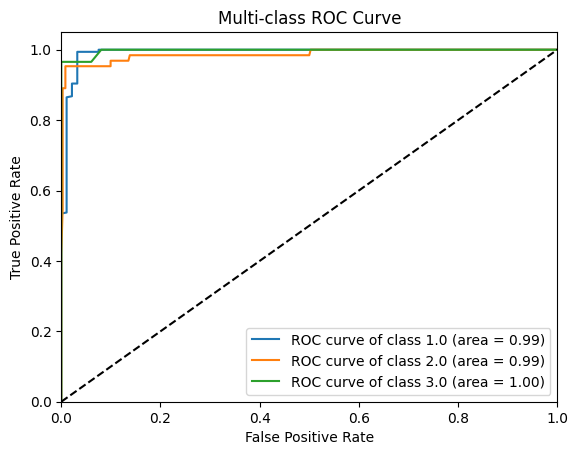

In [ ]:
!pip install scikit-learn matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier


# Assuming 'model' is your trained GradientBoostingClassifier
# Assuming 'X_test' and 'y_test' are your test data

# Binarize the labels for multi-class ROC
y_test_bin = label_binarize(y_test, classes=model.classes_)
n_classes = y_test_bin.shape[1]

# Create a OneVsRestClassifier to get probabilities for each class
classifier = OneVsRestClassifier(model)  # Using the existing 'model'
y_score = classifier.fit(X_train, y_train).predict_proba(X_test)

# Calculate ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure()
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC curve of class {model.classes_[i]} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.show()



In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.5],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0]
}
grid_search = GridSearchCV(model, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)
print("Best Parameters:", grid_search.best_params_)


Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.5],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0]
}
grid_search = GridSearchCV(model, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)
print("Best Parameters:", grid_search.best_params_)


Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}


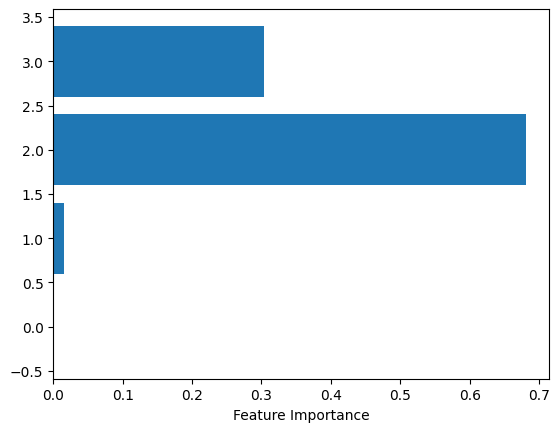

In [ ]:
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier # Importing the class
from sklearn.model_selection import train_test_split # Importing for data split

# Load or create your features (X) and target (y) here.
# Example with a dummy dataset:
from sklearn.datasets import load_iris
iris = load_iris()
X, y = iris.data, iris.target

# The following line is now using the loaded data:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the model
model = GradientBoostingClassifier()  # Creating the model instance
model.fit(X_train, y_train)  # Training the model

# Now you can access feature importances
importances = model.feature_importances_
plt.barh(range(len(importances)), importances)
plt.xlabel('Feature Importance')
plt.show()



In [ ]:
import joblib
joblib.dump(model, 'fetal_heart_rate_model.joblib')


['fetal_heart_rate_model.joblib']

In [ ]:
# Load with joblib
model = joblib.load('fetal_heart_rate_model.joblib')

# The original line was trying to open a file with a .pkl extension.
# Since the file was saved with .joblib, we use joblib.load instead.
#with open('fetal_heart_rate_model.pkl', 'rb') as file:
#    model = pickle.load(file)

In [ ]:
def predict_fetal_health(input_data):
    # Preprocess input_data here if necessary

    # Perform the prediction
    prediction = model.predict(input_data)
    return prediction


In [ ]:
import joblib

# Load the model
model = joblib.load('fetal_heart_rate_model.joblib')


In [ ]:
import joblib
from sklearn.preprocessing import StandardScaler

# Load the model
model = joblib.load('fetal_heart_rate_model.joblib')

# Assuming you did not save the scaler, you need to create and fit a new one.
# Replace 'X_train_original' with your original training data used to fit the model.
# If you did save the scaler, correct the filename in the next line.
# scaler = joblib.load('fetal_heart_rate_scaler.joblib')
scaler = StandardScaler()
scaler.fit(X_train)  # Replace X_train with your original training data

# Transform the new data
new_data_transformed = scaler.transform(new_data)

# Now you can use new_data_transformed for prediction with your model
# prediction = model.predict(new_data_transformed)


In [ ]:
import gc
gc.collect()


In [ ]:
# Example preprocessing
from sklearn.preprocessing import StandardScaler

# Assuming you saved your scaler during training
scaler = joblib.load('scaler.joblib')
new_data = scaler.transform(new_data)


In [ ]:
# Example new data input
# The original new_data had 5 features: [[120, 75, 15, 85, 140]]
# The model expects 4 features, so we need to adjust the input.

# Option 1: Remove one of the features
# For example, removing the last feature:
new_data = [[120, 75, 15, 85]]

# Option 2: If you have more data, ensure each data point has only 4 features.
# Example:
# new_data = [[120, 75, 15, 85], [110, 70, 12, 90], ...]

# Option 3 (If applicable): If the extra feature is irrelevant, you can consistently remove it
# during data preprocessing before training and prediction.

# Make a prediction
prediction = model.predict(new_data)
print("Predicted Class:", prediction[0])

# For probability of each class (optional)
probabilities = model.predict_proba(new_data)
print("Class Probabilities:", probabilities[0])



Predicted Class: 2
Class Probabilities: [1.78092891e-06 2.76934027e-05 9.99970526e-01]


In [ ]:
from sklearn.preprocessing import StandardScaler
import joblib

# Fit the scaler on the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Save the scaler
joblib.dump(scaler, 'scaler.joblib')


['scaler.joblib']

In [ ]:
import pandas as pd

# Example with multiple rows of new data
new_data_batch = pd.DataFrame([
    [120, 75, 15, 85, 140],
    [130, 70, 10, 90, 135],
    # More rows...
])

# Select the first 4 columns (features) to match the scaler's expectations
new_data_batch = new_data_batch[[0, 1, 2, 3]]  # Select columns 0, 1, 2, 3


# Apply any necessary preprocessing
new_data_batch = scaler.transform(new_data_batch)

# Predict for the batch
predictions = model.predict(new_data_batch)
print("Predictions for batch:", predictions)


Predictions for batch: [2 1]


In [ ]:
def make_prediction(new_data):
    # Load model and scaler
    model = joblib.load('fetal_heart_rate_model.joblib')
    scaler = joblib.load('scaler.joblib')

    # Preprocess new data
    # Select the first 4 features to match the scaler's expectations
    new_data = [row[:4] for row in new_data]  # Assuming the extra feature is the last one
    new_data = scaler.transform(new_data)

    # Predict
    prediction = model.predict(new_data)
    return prediction

# Example usage
new_data = [[120, 75, 15, 85, 140]]
print("Prediction:", make_prediction(new_data))



Prediction: [2]


In [ ]:
import joblib
import numpy as np

# Load the saved scaler and model
scaler = joblib.load('scaler.joblib')
model = joblib.load('fetal_heart_rate_model.joblib')

# Example new data - Ensure it has the correct number of features (4 in this case)
# If your actual new data has 5 features, you might need to select the relevant 4 or adjust your model/scaler accordingly.
new_data = np.array([[120, 75, 15, 85]])  # Removed the extra feature

# Transform new data using the scaler
new_data_transformed = scaler.transform(new_data)

# Use the transformed data for prediction
prediction = model.predict(new_data_transformed)
print("Predicted Class:", prediction[0])



In [ ]:
pip install --quiet flask gunicorn joblib)


In [ ]:
%time your_code_here
